# MIP brasileira de 12 setores: produção, demanda e atribuição de CO₂

Documento independente do exemplo calibrado da v4. Os fluxos monetários são os da **MIP oficial do IBGE de 2015, nível 12**, em R$ milhões correntes a preços básicos, sem calibração, fechamento artificial, supressão da diagonal ou substituição de valores. Usamos o sistema de produção nacional: a demanda final inclui exportações, e as emissões importadas não são atribuídas ao Brasil.

As emissões **são estimadas**, não medições publicadas na MIP. Mantemos os coeficientes de Sanguinet e Azzoni (2024) já adotados no projeto, interpolados entre 2011 e 2018. Para cada grupo de 12 atividades, somamos as emissões diretas estimadas das atividades de nível 67 e dividimos pela produção do grupo. A hipótese de compatibilidade monetária do projeto (fator 1, sem deflação efetiva) permanece uma limitação dos níveis ambientais. Não apresentamos essas estimativas como inventário oficial de emissões.

A figura mantém todas as 144 transações nacionais entre atividades, incluindo 12 laços, as 12 entregas finais e todas as parcelas positivas da matriz ambiental F. Áreas e espessuras são lineares, sem piso ou corte por relevância. Arquivos vetoriais preservam as ligações muito finas, que podem ser difíceis de distinguir em tamanho de página.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
from redes import dados,modelo

meta12=dados.entrada("mip_ibge_2015_12")
caminho12=dados.RAIZ_PROJETO/meta12["arquivo"]
dados.check_sha256(caminho12,meta12["sha256"])
t12=pd.read_excel(caminho12,sheet_name=None,header=None,engine="xlrd")
t67=dados.carregar_matriz_67("mip_ibge_2015_67")
x67=modelo.calcular_producao_bruta_67(t67)
codigos=t12["14"].iloc[5:17,0].astype(str).str.zfill(2).tolist()
nomes=t12["14"].iloc[5:17,1].tolist()
assert codigos==[f"{i:02d}" for i in range(1,13)]
assert [str(v).splitlines()[0] for v in t12["14"].iloc[3,2:14]]==codigos


SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_12.xls.original
SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_67.xls.original


## 1. Sistema monetário nacional observado

Extraímos V (Tabela 01), U e a demanda final nacional por produto (Tabela 03), e D (Tabela 13). Todas as classificações têm dimensão 12. Calculamos $x=V^T\mathbf1$, $Z=DU$, $y=Dy^{prod}$, $A=Z\,\mathrm{diag}(x)^{-1}$ e $L=(I-A)^{-1}$. Conferimos as identidades contábeis e as matrizes publicadas nas Tabelas 14 e 15. Nenhum saldo é redistribuído ou corrigido manualmente.

In [2]:
V12=t12["01"].iloc[5:17,7:19].to_numpy(float)
U12=t12["03"].iloc[5:17,3:15].to_numpy(float)
D12=t12["13"].iloc[5:17,2:14].to_numpy(float)
x12=V12.sum(axis=0)
Z12=D12@U12
y12=D12@t12["03"].iloc[5:17,22].to_numpy(float)
A12=Z12/x12[None,:]
L12=np.linalg.inv(np.eye(12)-A12)
np.testing.assert_allclose(D12,V12.T/V12.sum(axis=1)[None,:],rtol=1e-12,atol=1e-12)
np.testing.assert_allclose(Z12.sum(axis=1)+y12,x12,rtol=1e-12,atol=1e-8)
np.testing.assert_allclose(A12,t12["14"].iloc[5:17,2:14].to_numpy(float),rtol=1e-10,atol=1e-12)
np.testing.assert_allclose(L12,t12["15"].iloc[5:17,2:14].to_numpy(float),rtol=1e-10,atol=1e-12)
assert (x12>0).all() and (y12>0).all() and (Z12>=0).all()
assert np.count_nonzero(Z12)==144
assert max(abs(np.linalg.eigvals(A12)))<1


## 2. Agregação ambiental de 67 para 12 atividades

O mapeamento abaixo é explícito e cobre cada atividade uma única vez. Conferimos que a soma das produções das atividades de nível 67 coincide, grupo a grupo, com os valores publicados no nível 12. Para o grupo $g$, $c_g=\sum_{i\in g}\varphi_i x_i$ e $\varphi_g=c_g/x_g$.

A matriz $F=\mathrm{diag}(\varphi_{12})L_{12}\mathrm{diag}(y_{12})$ é calculada no **sistema oficial de nível 12**; não é uma soma de blocos da F de nível 67. A agregação produtiva pode alterar a distribuição pela demanda. As identidades $F\mathbf1=c$ e $\mathbf1^TF=u^T$ garantem a conservação do total dentro deste sistema.

In [3]:
grupos={
 "01":["0191","0192","0280"],
 "02":["0580","0680","0791","0792"],
 "03":[c for c in x67.index if 10<=int(c[:2])<=33],
 "04":["3500","3680"],
 "05":["4180"],
 "06":["4580"],
 "07":["4900","5000","5100","5280"],
 "08":["5800","5980","6100","6280"],
 "09":["6480"],
 "10":["6800"],
 "11":["5500","5600","6980","7180","7380","7700","7880","8000","8592","8692","9080","9480","9700"],
 "12":["8400","8591","8691"],
}
cobertura=[c for grupo in grupos.values() for c in grupo]
assert len(cobertura)==len(set(cobertura))==67 and set(cobertura)==set(x67.index)
np.testing.assert_allclose([x67.loc[grupos[g]].sum() for g in codigos],x12,rtol=0,atol=1e-8)
phi2011=dados.carregar_coeficientes_co2("sanguinet_azzoni_2011")[2011]
phi2018=dados.carregar_coeficientes_co2("sanguinet_azzoni_2018")[2018]
assert phi2011.index.equals(phi2018.index)
phi67=pd.Series((phi2011+4/7*(phi2018-phi2011)).to_numpy(),index=x67.index)
c67=phi67*x67
c12=np.array([c67.loc[grupos[g]].sum() for g in codigos])
phi12=c12/x12
F12=phi12[:,None]*L12*y12[None,:]
u12=F12.sum(axis=0)
np.testing.assert_allclose(F12.sum(axis=1),c12,rtol=1e-12,atol=1e-8)
np.testing.assert_allclose(u12.sum(),c12.sum(),rtol=1e-12)
np.testing.assert_allclose(c12.sum(),c67.sum(),rtol=1e-12)
F_verificada=np.column_stack([phi12*np.linalg.solve(np.eye(12)-A12,np.eye(12)[:,j]*y12[j]) for j in range(12)])
np.testing.assert_allclose(F_verificada,F12,rtol=1e-12,atol=1e-8)
assert (F12>0).all()
contas=pd.DataFrame({"atividade":nomes,"x_r_milhoes":x12,"y_r_milhoes":y12,
    "phi_gg_por_r_milhao":phi12,"c_gg":c12,"u_gg":u12},index=codigos)
display(contas)
print("CO₂ total nas duas contas (Gg):",c12.sum(),u12.sum())


SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2011.csv
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2018.csv
CO₂ total nas duas contas (Gg): 683696.0414285716 683696.0414285716


,atividade,x_r_milhoes,y_r_milhoes,phi_gg_por_r_milhao,c_gg,u_gg
01,Agropecuária,"478,730.00","226,393.23",0.05,"22,460.22","23,394.75"
02,Indústrias extrativas,"260,573.00","115,643.04",0.02,"6,086.31","8,869.10"
03,Indústrias de transformação,"2,776,460.00","1,424,549.72",0.08,"221,954.90","229,196.62"
04,"Eletricidade e gás, água, esgoto e gestão de resíduos","323,598.00","103,573.79",0.34,"108,422.89","51,876.47"
05,Construção,"632,308.00","529,102.09",0.06,"38,841.78","61,632.12"
06,Comércio,"1,100,763.00","670,856.18",0.02,"26,732.82","44,174.32"
07,"Transporte, armazenagem e correio","505,417.00","158,076.02",0.03,"15,157.23","13,718.19"
08,Informação e comunicação,"350,466.00","169,361.10",0.12,"41,319.33","29,340.70"
09,"Atividades financeiras, de seguros e serviços relacionados","574,611.00","277,120.63",0.03,"16,417.46","17,551.35"
10,Atividades imobiliárias,"545,929.00","456,009.77",0.03,"18,717.57","18,679.37"


## 3. Duas redes e Sankey completos

Os 12 setores e a Demanda Final ocupam as mesmas posições nas duas redes. A área é proporcional a x; em Demanda Final, a $\sum y$. As 144 transações Z (incluindo os laços da diagonal) e as 12 entregas y são desenhadas em ambos os quadros. A espessura monetária é linear e usa uma única constante, sem piso. Posições, curvaturas e opacidade são apenas escolhas de apresentação.

I–XII identificam as emissões diretas c e XIII–XXIV as atribuições u. Na rede da demanda os códigos ficam nos círculos setoriais, para evitar 12 identificadores sobrepostos na chegada à Demanda Final. O Sankey nomeia os mesmos setores nas duas margens e usa cada F_ij, sem corte. As cores dos círculos e barras usam os mesmos limites lineares, definidos pelos 24 valores de c e u. Os nomes são abreviados na figura; os nomes oficiais constam das contas exportadas.

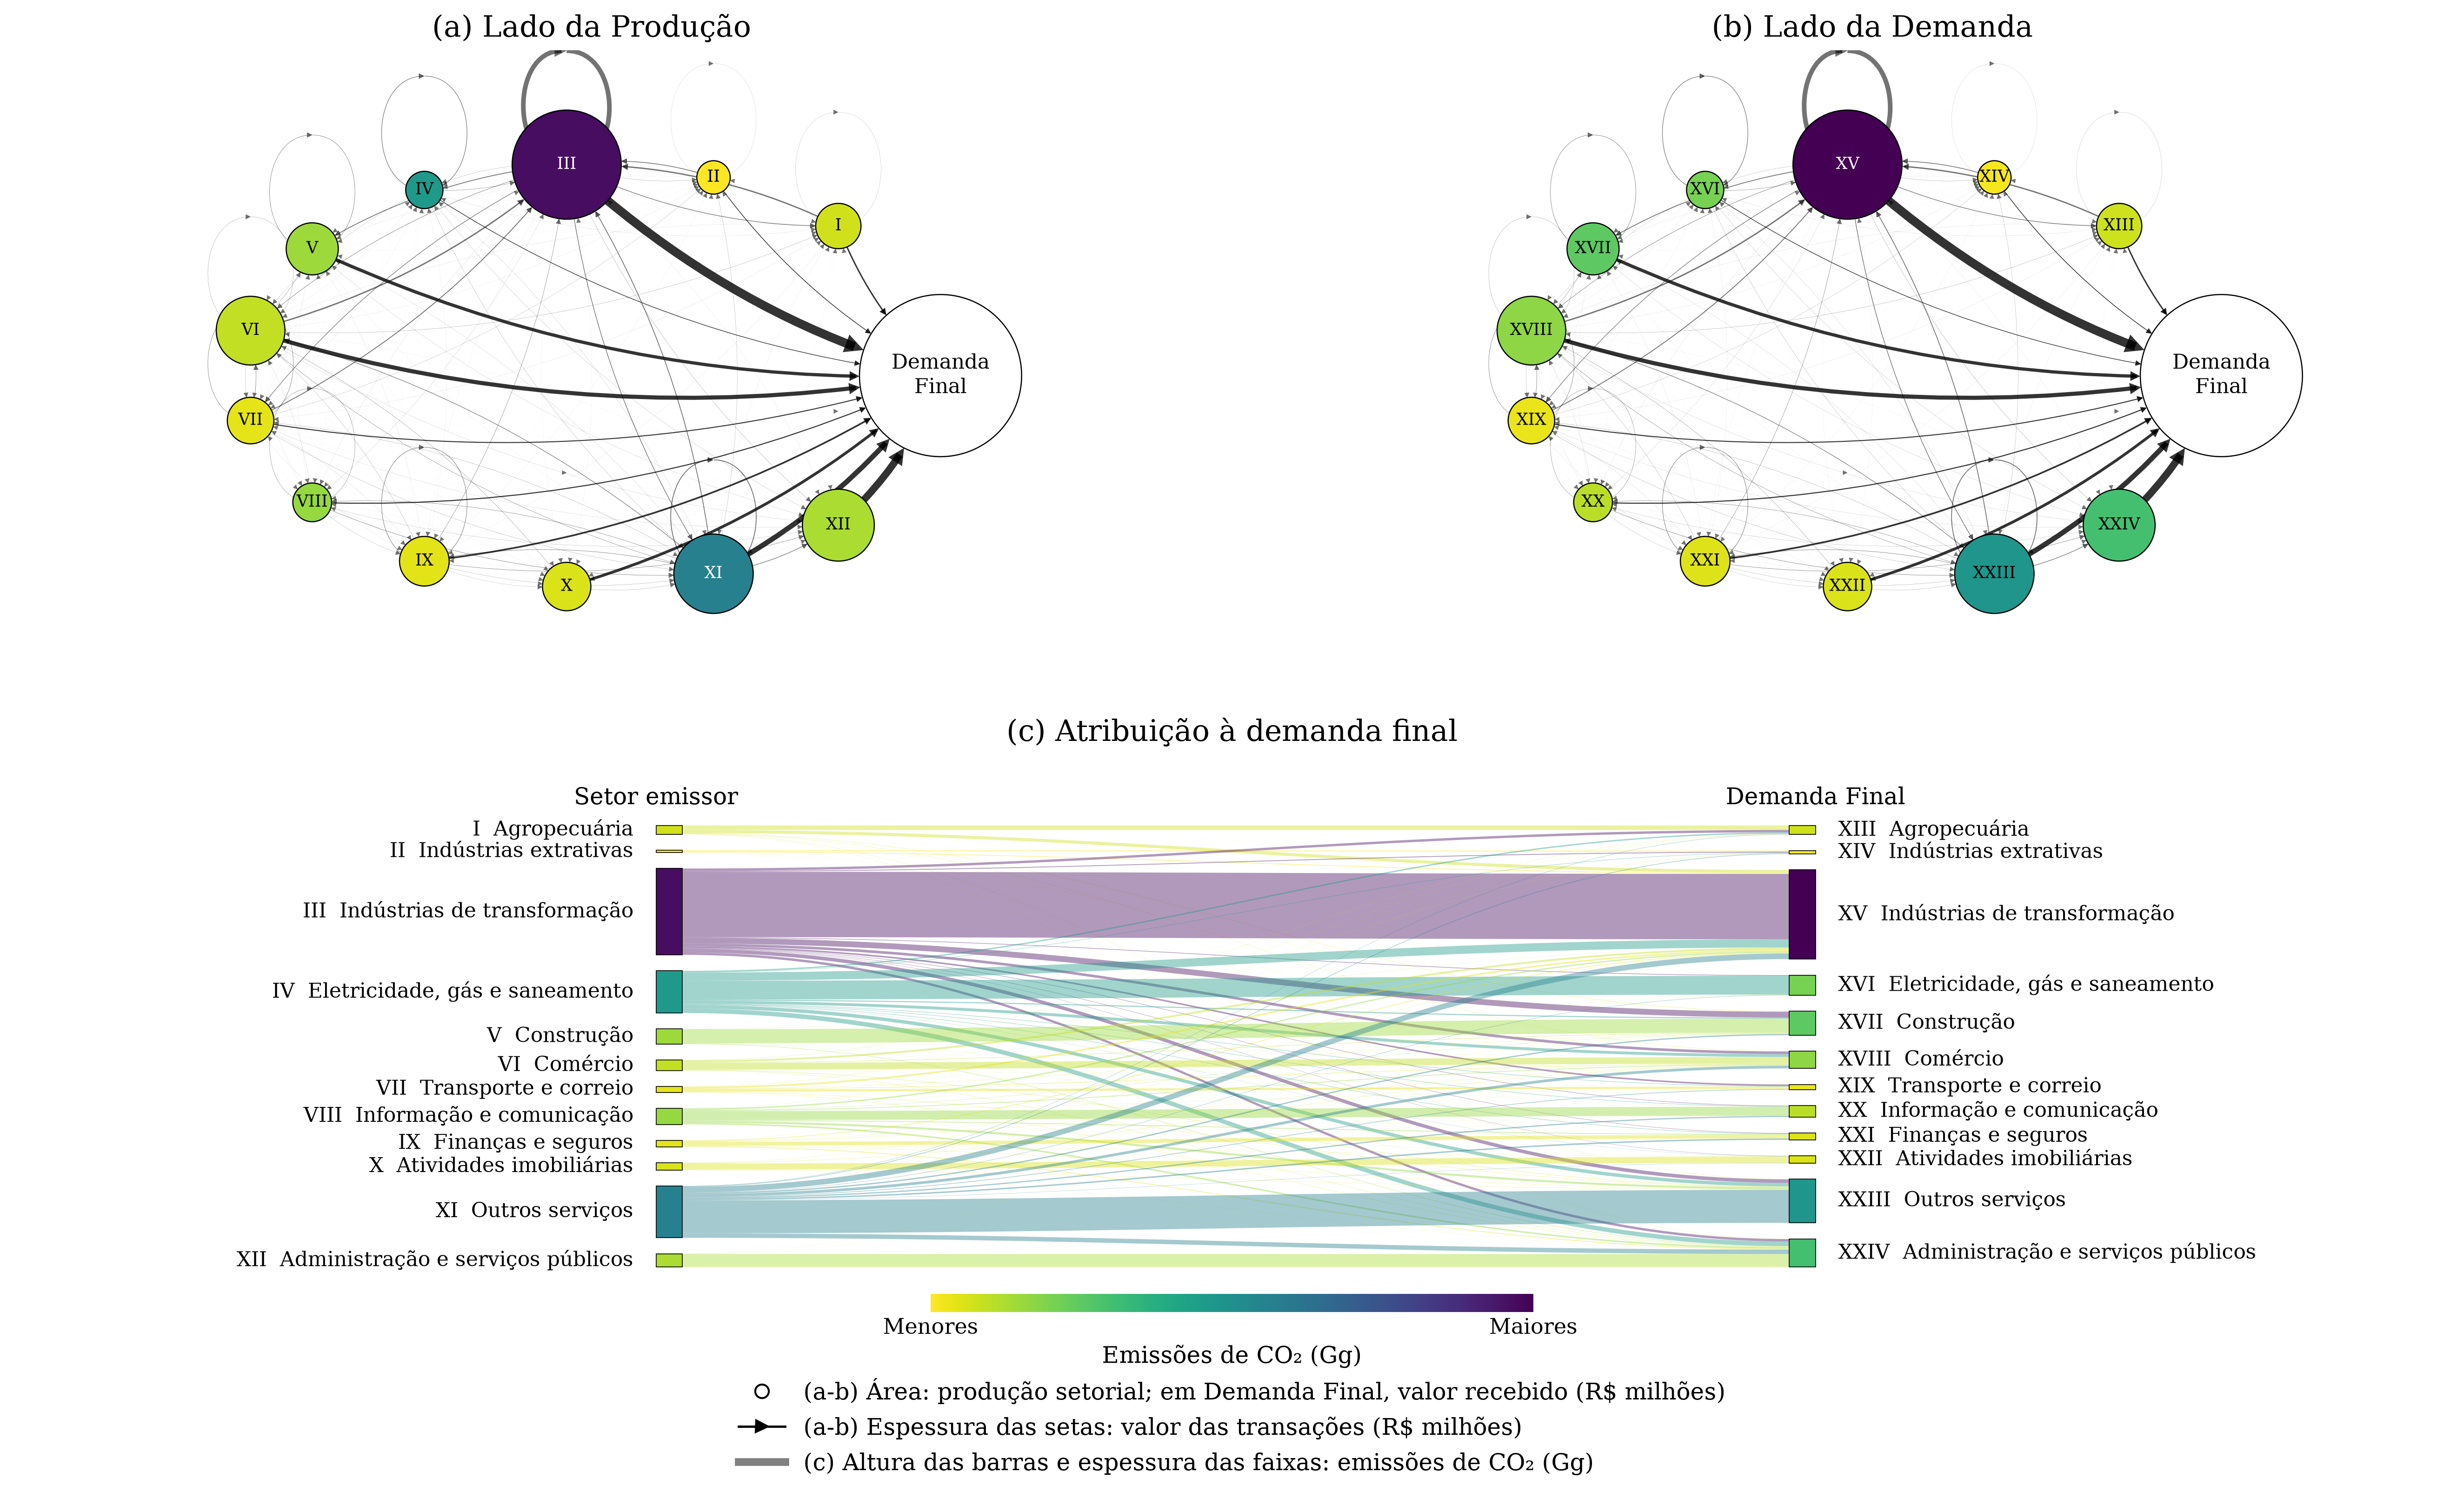

In [4]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.path import Path as Caminho
from matplotlib.patches import PathPatch,Rectangle

rotulos=["Agropecuária","Indústrias extrativas","Indústrias de transformação",
 "Eletricidade, gás e saneamento","Construção","Comércio","Transporte e correio",
 "Informação e comunicação","Finanças e seguros","Atividades imobiliárias",
 "Outros serviços","Administração e serviços públicos"]
romanos_c=["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]
romanos_u=["XIII","XIV","XV","XVI","XVII","XVIII","XIX","XX","XXI","XXII","XXIII","XXIV"]
rede12=nx.DiGraph()
rede12.add_nodes_from(codigos+["DF"])
for i,origem in enumerate(codigos):
    for j,destino in enumerate(codigos):
        if Z12[i,j]>0:rede12.add_edge(origem,destino,valor=Z12[i,j],tipo="Z")
    if y12[i]>0:rede12.add_edge(origem,"DF",valor=y12[i],tipo="y")
assert rede12.number_of_nodes()==13 and rede12.number_of_edges()==156
assert nx.number_of_selfloops(rede12)==12
angulos=np.linspace(np.pi/4,7*np.pi/4,12)
posicoes={c:(10.725*np.cos(a),6.5*np.sin(a)) for c,a in zip(codigos,angulos)}
posicoes["DF"]=(10.725,0)
valores_nos=np.r_[x12,y12.sum()]
areas12=7000*valores_nos/y12.sum()
escala_setas=4.5/max(Z12.max(),y12.max())
paleta12=plt.get_cmap("viridis_r")
norma12=Normalize(vmin=min(c12.min(),u12.min()),vmax=max(c12.max(),u12.max()))
fig12=plt.figure(figsize=(18,10.6))
for x_eixo,titulo,conta,romanos in [(.015,"(a) Lado da Produção",c12,romanos_c),
                                  (.525,"(b) Lado da Demanda",u12,romanos_u)]:
    ax=fig12.add_axes([x_eixo,.54,.46,.44])
    ax.set(xlim=(-14,14),ylim=(-10,10),aspect="equal")
    ax.set_title(titulo,fontfamily="DejaVu Serif",fontsize=15,pad=7)
    for origem,destino,d in rede12.edges(data=True):
        setas=nx.draw_networkx_edges(rede12,posicoes,ax=ax,edgelist=[(origem,destino)],
            nodelist=list(rede12),node_size=areas12,width=d["valor"]*escala_setas,
            edge_color="black",alpha=.80 if d["tipo"]=="y" else .55,
            arrows=True,arrowstyle="-|>",arrowsize=6,
            connectionstyle="arc3,rad=0.12",min_source_margin=1,min_target_margin=1)
        for seta in setas:seta.set_capstyle("butt");seta.set_joinstyle("miter")
    cores=[paleta12(norma12(v)) for v in conta]+[(1,1,1,1)]
    nx.draw_networkx_nodes(rede12,posicoes,ax=ax,nodelist=list(rede12),node_size=areas12,
        node_color=cores,edgecolors="black",linewidths=.6)
    for i,codigo in enumerate(codigos):
        r,g,b,_=cores[i]
        ax.text(*posicoes[codigo],romanos[i],ha="center",va="center",fontsize=8.5,
            fontfamily="DejaVu Serif",color="white" if .2126*r+.7152*g+.0722*b<.45 else "black")
    ax.text(*posicoes["DF"],"Demanda\nFinal",ha="center",va="center",fontsize=10.5,fontfamily="DejaVu Serif")
    ax.axis("off")
    assert len(ax.patches)==156  # todas as setas, incluindo os 12 laços

# Sankey: todas as 144 parcelas F_ij; escala única de altura nas duas margens.
escala_F=1/F12.sum()
alturas_c=c12*escala_F;alturas_u=u12*escala_F
gap=.06;altura_total=1+11*gap
topos_c=altura_total-np.r_[0,np.cumsum(alturas_c[:-1])+gap*np.arange(1,12)]
topos_u=altura_total-np.r_[0,np.cumsum(alturas_u[:-1])+gap*np.arange(1,12)]
cursor_c=topos_c.copy();cursor_u=topos_u.copy()
axF=fig12.add_axes([.015,.15,.97,.34])
x_esq,x_dir,largura=0,6,.14
contagem_faixas=0
for i in range(12):
    for j in range(12):
        if F12[i,j]==0:continue
        h=F12[i,j]*escala_F;yc,yu=cursor_c[i],cursor_u[j]
        vertices=[(x_esq+largura,yc),(2.5,yc),(3.7,yu),(x_dir,yu),
                  (x_dir,yu-h),(3.7,yu-h),(2.5,yc-h),(x_esq+largura,yc-h),(x_esq+largura,yc)]
        cods=[Caminho.MOVETO,Caminho.CURVE4,Caminho.CURVE4,Caminho.CURVE4,
              Caminho.LINETO,Caminho.CURVE4,Caminho.CURVE4,Caminho.CURVE4,Caminho.CLOSEPOLY]
        axF.add_patch(PathPatch(Caminho(vertices,cods),facecolor=paleta12(norma12(c12[i])),
            alpha=.42,edgecolor="none"))
        cursor_c[i]-=h;cursor_u[j]-=h;contagem_faixas+=1
np.testing.assert_allclose(cursor_c,topos_c-alturas_c,atol=1e-12)
np.testing.assert_allclose(cursor_u,topos_u-alturas_u,atol=1e-12)
assert contagem_faixas==144
for valores,alturas,topos,x_barra,romanos,lado in [
    (c12,alturas_c,topos_c,x_esq,romanos_c,"esq"),
    (u12,alturas_u,topos_u,x_dir,romanos_u,"dir")]:
    for i,nome in enumerate(rotulos):
        axF.add_patch(Rectangle((x_barra,topos[i]-alturas[i]),largura,alturas[i],
            facecolor=paleta12(norma12(valores[i])),edgecolor="black",linewidth=.4))
        axF.text(x_barra-.12 if lado=="esq" else x_barra+largura+.12,topos[i]-alturas[i]/2,
            romanos[i]+"  "+nome,ha="right" if lado=="esq" else "left",va="center",
            fontfamily="DejaVu Serif",fontsize=10.5)
assert len(axF.patches)==144+24  # faixas e barras das duas margens
axF.text(x_esq,altura_total+.08,"Setor emissor",ha="center",fontfamily="DejaVu Serif",fontsize=12)
axF.text(x_dir+largura,altura_total+.08,"Demanda Final",ha="center",fontfamily="DejaVu Serif",fontsize=12)
axF.set(xlim=(-3.4,9.5),ylim=(-.04,altura_total+.19));axF.axis("off")
fig12.text(.5,.513,"(c) Atribuição à demanda final",ha="center",fontfamily="DejaVu Serif",fontsize=15)
ax_cor=fig12.add_axes([.38,.127,.24,.012])
barra=fig12.colorbar(ScalarMappable(norm=norma12,cmap=paleta12),cax=ax_cor,
    orientation="horizontal",ticks=[norma12.vmin,norma12.vmax])
barra.ax.set_xticklabels(["Menores","Maiores"],fontfamily="DejaVu Serif",fontsize=11)
barra.ax.tick_params(length=0,pad=3);barra.outline.set_visible(False)
barra.set_label("Emissões de CO₂ (Gg)",fontfamily="DejaVu Serif",fontsize=12,labelpad=3)
legenda=[Line2D([],[],marker="o",linestyle="none",markersize=7,markerfacecolor="white",markeredgecolor="black",
    label="(a-b) Área: produção setorial; em Demanda Final, valor recebido (R$ milhões)"),
    Line2D([],[],color="black",linewidth=1.2,marker=">",markevery=[1],
    label="(a-b) Espessura das setas: valor das transações (R$ milhões)"),
    Line2D([],[],color="gray",linewidth=4,label="(c) Altura das barras e espessura das faixas: emissões de CO₂ (Gg)")]
fig12.legend(handles=legenda,loc="lower center",frameon=False,
    prop={"family":"DejaVu Serif","size":12},labelspacing=.5,bbox_to_anchor=(.5,.002))
pasta12=Path("outputs/mip12_real");pasta12.mkdir(parents=True,exist_ok=True)
for ext in ["pdf","svg","png"]:fig12.savefig(pasta12/f"redes_sankey_mip12.{ext}",dpi=300,bbox_inches="tight")
contas.to_csv(pasta12/"contas_12.csv")
for nome,matriz in [("Z",Z12),("A",A12),("L",L12),("F",F12)]:
    pd.DataFrame(matriz,index=codigos,columns=codigos).to_csv(pasta12/f"{nome}_12.csv")
pd.DataFrame([{"atividade67":c,"grupo12":g} for g,cs in grupos.items() for c in cs]).to_csv(pasta12/"correspondencia_67_12.csv",index=False)
proveniencia={"entradas":[dados.entrada(k) for k in ["mip_ibge_2015_12","mip_ibge_2015_67","sanguinet_azzoni_2011","sanguinet_azzoni_2018"]],
    "Z_positivos":int(np.count_nonzero(Z12)),"entregas_finais":int(np.count_nonzero(y12)),
    "F_positivos":contagem_faixas,"emissoes_total_gg":float(c12.sum()),
    "metodo":"MIP oficial nível 12; phi12 pela soma das emissões diretas estimadas do nível 67 dividida por x12; sem calibração monetária"}
(pasta12/"proveniencia.json").write_text(json.dumps(proveniencia,ensure_ascii=False,indent=2),encoding="utf-8")
plt.show()
